# One CloudSat overpass, end to end

`pixi run build` maps one function over all 276 overpasses in CIRA's 25 km list. This notebook runs the same steps by hand for one storm, so every intermediate array can be inspected.

The problem it solves: a CloudSat granule is a whole orbit (37,082 radar profiles, ~99 minutes, ~14 MB per field). A cyclone occupies a few minutes of it. We want just that slice, georeferenced, on a fixed height grid, in a form small enough to commit to git and draw in a browser.

Default case: Hurricane **Earl**, 2010-08-31, granule 23094, Category 4.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from cloudsat_cyclone_db.cloudsat_opendap import (
    GEOPROF, granule_path, granule_start, opendap_session, read_env, read_geolocation, read_profiles,
)
from cloudsat_cyclone_db.curtains import (
    HALF_WIDTH_KM, curtain_grid, dequantize_dbz, nearest_bins, target_heights_m,
)
from cloudsat_cyclone_db.overpasses import (
    along_track_km, haversine_km, match_storm, read_cira_overpasses, read_ibtracs, storm_center, storm_tracks, window,
)

Display and selection settings live here, as plain globals.

In [2]:
ROOT = Path('..')
OVERPASS_ID = '23094_EARL'
XLIM_KM = 500
DBZ_RANGE = (-30, 20)
CMAP = 'Blues_r'
FIGSIZE = (12, 3.6)

## 1. The CIRA overpass list

`tcs-25km.txt` gives the storm name, granule number, date and best-track intensity for each overpass. Its basin column is broken (`CS/20` on every row), so the basin comes from IBTrACS later.

In [3]:
rows = read_cira_overpasses().set_index('id')
row = rows.loc[OVERPASS_ID]
row

storm                     EARL
granule                  23094
date                2010-08-31
cira_min_dist_km           0.5
wind_ms                   59.2
pressure_mb              933.0
shear_kt                  17.2
sst_c                     29.7
Name: 23094_EARL, dtype: object

## 2. Find the granule file

The THREDDS catalog listing is public, and filenames encode the start time (`YYYYDDDHHMMSS_granule_...`). An orbit can start the day before the overpass date, so both days are searched.

In [4]:
path = granule_path(GEOPROF, int(row.granule), row.date)
path, granule_start(path)

('2B-GEOPROF.P1_R05/2010/243/2010243044728_23094_CS_2B-GEOPROF_GRANULE_P1_R05_E03_F00.hdf',
 datetime.datetime(2010, 8, 31, 4, 47, 28, tzinfo=datetime.timezone.utc))

## 3. Geolocation over OPeNDAP

Only four small 1-D fields are read for the whole orbit: latitude, longitude, `Profile_time` (seconds since granule start) and `UTC_start` (seconds since midnight). Absolute time per profile = midnight + `UTC_start` + `Profile_time`. Profiles are 0.16 s apart; at ~7 km/s ground speed that is ~1.1 km.

In [5]:
session = opendap_session(read_env(ROOT / '.env'))
geo = read_geolocation(session, path)
dt = np.diff(geo['time'])
along = along_track_km(geo['lat'], geo['lon'])
{'n_profiles': geo['lat'].size, 'dt_s': float(np.median(dt)), 'orbit_minutes': float((geo['time'][-1] - geo['time'][0]) / 60),
 'spacing_km': float(np.median(np.diff(along))), 'ground_speed_km_s': float(np.median(np.diff(along)) / np.median(dt))}

{'n_profiles': 37082,
 'dt_s': 0.160003662109375,
 'orbit_minutes': 98.882666015625,
 'spacing_km': 1.0914431818891899,
 'ground_speed_km_s': 6.82136375818138}

## 4. Where was the storm center when CloudSat flew over?

IBTrACS (= NHC HURDAT2 for the Atlantic) gives 3-hourly fixes. Interpolating the fixes to **each profile's own time** gives the storm center CloudSat should be compared against. The closest approach is the argmin of the great-circle distance.

CIRA's list says 0.5 km for Earl; the official best track at the actual crossing time says about 50 km. Across the first batch, CIRA's numbers matched the storm position at the *granule start time* better (median error 4.4 km) than at the crossing time (14.8 km), so CIRA's distances are not directly comparable to ours.

In [6]:
tracks = storm_tracks(read_ibtracs(ROOT / 'data/raw/ibtracs.since1980.list.v04r01.csv'))
sid, distance = match_storm(tracks, row.storm, geo)
center = int(np.argmin(distance))
{'sid': sid, 'ours_km': round(float(distance[center]), 1), 'cira_km': row.cira_min_dist_km,
 'cloudsat_at': (round(float(geo['lat'][center]), 3), round(float(geo['lon'][center]), 3)),
 'storm_at': tuple(round(float(v[0]), 3) for v in storm_center(tracks[sid], geo['time'][center:center + 1]))}

{'sid': '2010236N12341',
 'ours_km': 49.8,
 'cira_km': np.float64(0.5),
 'cloudsat_at': (20.142, -66.002),
 'storm_at': (20.235, -66.469)}

## 5. Read only the ±1000 km window

The window is set on along-track distance, then three 2-D fields are read for just those rows: `Radar_Reflectivity` (int16, dBZ × 100, missing = −8888), `CPR_Cloud_mask` (int8, ≥ 20 means a confident echo) and `Height` (int16, metres above the geoid, per profile and bin).

In [7]:
start, stop = window(along, center, HALF_WIDTH_KM)
profiles = read_profiles(session, path, start, stop)
{k: (v.shape, str(v.dtype)) for k, v in profiles.items()}, (start, stop), round(float(along[stop - 1] - along[start]), 1)

({'dbz100': ((1822, 125), 'int16'),
  'cloud_mask': ((1822, 125), 'int8'),
  'height_m': ((1822, 125), 'int16')},
 (34086, 35908),
 1999.4)

## 6. Range bins to a fixed height grid, then 8 bits

Each profile's 125 range bins are 240 m apart, but their heights shift from profile to profile with the surface and orbit. Mapping every profile onto one 0-20 km grid (84 levels × 240 m) by nearest bin makes the curtain a plain 2-D array.

Then quantize: `q = 0` means no echo; otherwise `dBZ = -35 + 0.25 (q - 1)`. Rounding to the nearest 0.25 dB step means the error is at most 0.125 dB. The check below measures it.

In [8]:
grid = curtain_grid(profiles)
index = nearest_bins(profiles['height_m'], target_heights_m())
raw = np.take_along_axis(profiles['dbz100'], index.clip(0), axis=1).T / 100
kept = grid > 0
error = np.abs(dequantize_dbz(grid) - raw)[kept & (raw <= 28.5) & (raw >= -35)]
{'grid': grid.shape, 'bytes': grid.nbytes, 'echo_fraction': round(float(kept.mean()), 3), 'max_quantization_error_db': round(float(error.max()), 4)}

{'grid': (84, 1822),
 'bytes': 153048,
 'echo_fraction': 0.325,
 'max_quantization_error_db': 0.12}

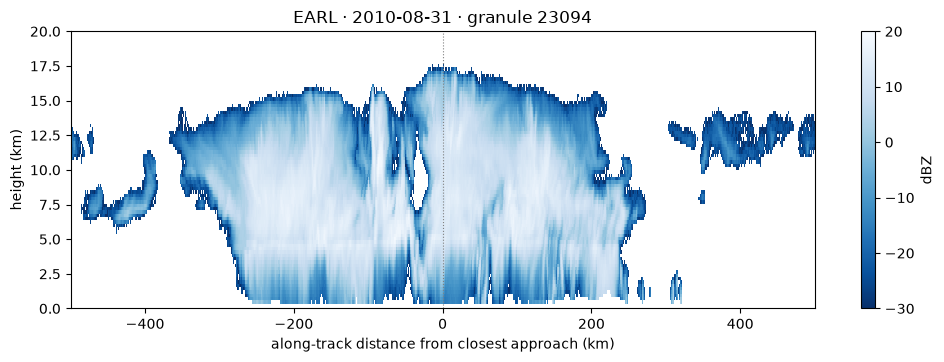

In [9]:
rel = along[start:stop] - along[center]
heights_km = target_heights_m() / 1000
fig, ax = plt.subplots(figsize=FIGSIZE)
mesh = ax.pcolormesh(rel, heights_km, dequantize_dbz(grid), vmin=DBZ_RANGE[0], vmax=DBZ_RANGE[1], cmap=CMAP, shading='nearest')
fig.colorbar(mesh, ax=ax, label='dBZ')
ax.axvline(0, color='0.5', lw=0.8, ls=':')
ax.set(xlim=(-XLIM_KM, XLIM_KM), ylim=(0, 20), xlabel='along-track distance from closest approach (km)', ylabel='height (km)',
       title=f'{row.storm} · {row.date} · granule {int(row.granule)}')
plt.show()

## 7. Ground track and best track

The curtain is a moving snapshot: the 2000 km window takes `2000 / 7 ≈ 4.8` minutes to fly, while a storm moving at 5 m/s shifts about 1.4 km in that time, which is roughly one radar footprint.

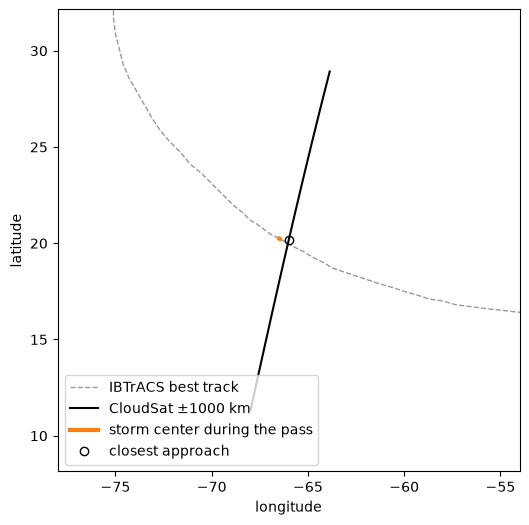

{'pass_minutes': 4.86, 'storm_moved_km': 1.91}

In [10]:
t = geo['time'][start:stop]
track = tracks[sid]
lat_c, lon_c = storm_center(track, t)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(track['LON'], track['LAT'], '--', color='0.6', lw=1, label='IBTrACS best track')
ax.plot(geo['lon'][start:stop], geo['lat'][start:stop], color='k', lw=1.5, label='CloudSat ±1000 km')
ax.plot(lon_c, lat_c, color='tab:orange', lw=3, label='storm center during the pass')
ax.plot(geo['lon'][center], geo['lat'][center], 'o', mfc='none', mec='k', label='closest approach')
ax.set(xlim=(geo['lon'][center] - 12, geo['lon'][center] + 12), ylim=(geo['lat'][center] - 12, geo['lat'][center] + 12),
       xlabel='longitude', ylabel='latitude', aspect='equal')
ax.legend(loc='lower left')
plt.show()
{'pass_minutes': round(float((t[-1] - t[0]) / 60), 2), 'storm_moved_km': round(float(haversine_km(lat_c[0], lon_c[0], lat_c[-1], lon_c[-1])), 2)}

## 8. What the site stores

`curtain_header` and `write_curtain` turn the arrays above into `site/data/curtains/<id>.json` (lat, lon, time and distance per profile, plus the overpass record) and `<id>.u8` (the uint8 grid, 84 × n_profiles, row 0 = lowest height). `pixi run build` does this for every overpass; `pixi run serve` shows them.